# Tuần 03 — Thực hành kNN: 4 bài

Demo `01_Demo-kNN.ipynb` dừng ở việc **vote nhãn cho một mẫu test**.

Notebook này có **4 bài**. Mỗi bài là một bộ dữ liệu trên Kaggle. Cả 4 bài đều làm.

Viết hàm kNN một lần ở phần chung (NumPy, không dùng `KNeighborsClassifier`), rồi áp vào từng bài. Điền các ô có `???`. Giữ `np.random.seed(3000)`.

Tải đủ 4 file, đặt vào thư mục `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Iris Species | https://www.kaggle.com/datasets/uciml/iris | `data/Iris.csv` |
| 2 | Palmer Penguins | https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data | `data/penguins_size.csv` |
| 3 | Heart Failure Prediction | https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction | `data/heart.csv` |
| 4 | Mushroom Classification | https://www.kaggle.com/datasets/uciml/mushroom-classification | `data/mushrooms.csv` |


In [14]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder

np.set_printoptions(precision=3, suppress=True)


## Phần chung — hàm kNN

Các bài bên dưới gọi lại 4 hàm này.

**Chuẩn hóa min–max**, min/max tính trên từng cột của `x_train`, rồi áp cùng hai mốc đó cho `x_test`. Cột nào `max == min` thì giữ nguyên.

$$
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

**Khoảng cách Euclid** từ một mẫu test tới mọi dòng train:

$$
d_i = \sqrt{\sum_j (test_j - train_{i,j})^2}
$$

**Một mẫu:** lấy `K` chỉ số gần nhất (`np.argsort`), vote nhãn xuất hiện nhiều nhất. Hòa thì `np.argmax` trên `counts` chọn nhãn có mã nhỏ hơn.

**Cả tập test:** gọi dự đoán từng mẫu, trả về mảng nhãn cùng độ dài `x_test`.


In [15]:
def chuan_hoa_minmax(x_train, x_test):
    x_min = np.min(x_train, axis=0)
    x_max = np.max(x_train, axis=0)
    mau = x_max - x_min
    mau[mau == 0] = 1.0
    
    x_train_scaled = (x_train - x_min) / mau
    x_test_scaled = (x_test - x_min) / mau
    return x_train_scaled, x_test_scaled


def tinh_khoang_cach(test_s, x_train):
    """test_s shape (n_feature,), x_train shape (n_train, n_feature).
    Trả về khoảng cách shape (n_train,).
    """
    return np.sqrt(np.sum((x_train - test_s) ** 2, axis=1))


def du_doan_1_mau(test_s, x_train, y_train, K):
    kc = tinh_khoang_cach(test_s, x_train)
    k_indices = np.argsort(kc)[:K]
    k_labels = y_train[k_indices]
    
    vals, counts = np.unique(k_labels, return_counts=True)
    max_count = np.max(counts)
    best_labels = vals[counts == max_count]
    return best_labels[0]


def du_doan_tap(x_test, x_train, y_train, K):
    y_pred = [du_doan_1_mau(test_s, x_train, y_train, K) for test_s in x_test]
    return np.array(y_pred)


In [16]:
def chia_train_test(X, Y, ty_le=0.8, seed=3000):
    np.random.seed(seed)
    rand_indices = np.arange(len(Y))
    np.random.shuffle(rand_indices)
    n_train = int(ty_le * len(Y))
    train_idx = rand_indices[:n_train]
    test_idx = rand_indices[n_train:]
    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]


def accuracy(y_pred, y_test):
    return np.mean(y_pred == y_test)


def ve_accuracy_theo_K(x_train, y_train, x_test, y_test, ds_K=None):
    if ds_K is None:
        ds_K = [1, 3, 5, 7, 9, 11, 13, 15]
    ds_acc = [accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test) for K in ds_K]
    print(list(zip(ds_K, np.round(ds_acc, 3))))
    plt.figure(figsize=(6, 4))
    plt.plot(ds_K, ds_acc, marker='o')
    plt.xlabel('K')
    plt.ylabel('accuracy')
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.show()
    return ds_K, ds_acc


---

# Bài 1 — Iris

Nguồn: https://www.kaggle.com/datasets/uciml/iris

File `data/Iris.csv`. 150 bông, 3 loài.

Cột: `Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species`.

- Bỏ cột `Id`. Đó là số thứ tự, không phải số đo của hoa.
- Bốn cột đo là số (cm). Nhãn `Species` là chữ: dùng `LabelEncoder`.
- Chuẩn hóa min–max, rồi so sánh accuracy khi **có** và **không** chuẩn hóa (`K=5`).
- In kiểm tra mẫu test đầu tiên (khoảng cách K láng giềng, nhãn của họ, nhãn đoán, nhãn thật), rồi vẽ accuracy theo K.


In [17]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
import kagglehub
import os

path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

raw_iris = np.genfromtxt(
    os.path.join(path, "Iris.csv"),
    delimiter=",",
    dtype=str,
    skip_header=1
)

print(raw_iris.shape)
print(raw_iris[0])

# X: bỏ Id và Species
X_iris = raw_iris[:, 1:-1].astype(float)

# Y: chuyển Species từ chuỗi -> số
Y_iris = LabelEncoder().fit_transform(raw_iris[:, -1])

print(X_iris.shape, Y_iris.shape)
print(np.unique(Y_iris, return_counts=True))

c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 3.60k/3.60k [00:00<00:00, 1.84MB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\uciml\iris\versions\2
(150, 6)
['1' '5.1' '3.5' '1.4' '0.2' 'Iris-setosa']
(150, 4) (150,)
(array([0, 1, 2], dtype=int64), array([50, 50, 50], dtype=int64))


Khoảng cách K láng giềng gần nhất: [0.114 0.341 0.349 0.365 0.419]
Nhãn K láng giềng: [2 2 2 2 2]
Nhãn dự đoán: 2
Nhãn thật: 2
accuracy K=5, đã chuẩn hóa: 0.9666666666666667
accuracy K=5, chưa chuẩn hóa: 0.9666666666666667
[(1, 0.967), (3, 0.967), (5, 0.967), (7, 0.967), (9, 0.967), (11, 0.967), (13, 0.967), (15, 0.967)]


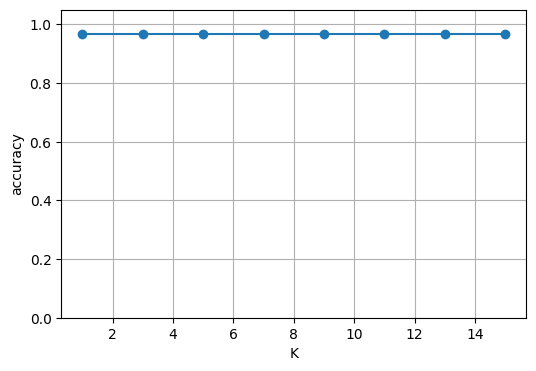

([1, 3, 5, 7, 9, 11, 13, 15],
 [0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667,
  0.9666666666666667])

In [18]:
x_train, y_train, x_test, y_test = chia_train_test(X_iris, Y_iris)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

K = 5
# TODO: in K khoảng cách nhỏ nhất, nhãn K láng giềng, nhãn dự đoán, y_test[0]
kc = tinh_khoang_cach(x_test_s[0], x_train_s)
idx_nn = np.argsort(kc)[:K]
print('Khoảng cách K láng giềng gần nhất:', kc[idx_nn])
print('Nhãn K láng giềng:', y_train[idx_nn])
print('Nhãn dự đoán:', du_doan_1_mau(x_test_s[0], x_train_s, y_train, K))
print('Nhãn thật:', y_test[0])

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, K), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 1**

1. `X` có bao nhiêu dòng, bao nhiêu cột? Có bao nhiêu lớp?
2. Accuracy tại `K=5` khi có chuẩn hóa và khi không chuẩn hóa chênh nhau thế nào? Vì sao với Iris mức chênh thường nhỏ?
3. Vì sao không đưa cột `Id` vào feature?


In [19]:
# Bài 1
# 1. X có 150 dòng, 4 cột. Có 3 lớp nhãn.
# 2. Accuracy chênh lệch rất nhỏ (hoặc bằng nhau) vì các đặc trưng của Iris đo cùng đơn vị (cm) và có biên độ giá trị tương đồng nhau.
# 3. Vì cột Id chỉ là số thứ tự tăng dần của các mẫu, không chứa thông tin đặc trưng đo lường về hình thái học của hoa.


---

# Bài 2 — Palmer Penguins

Nguồn: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

File `data/penguins_size.csv`. Đoán loài chim cánh cụt.

Cột: `species`, `island`, `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

- Bỏ mọi dòng có ô trống hoặc `NA`.
- Nhãn là `species`.
- `island` và `sex` là chữ: `LabelEncoder` **từng cột**.
- Bốn cột đo là số: `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`.
- Bắt buộc chuẩn hóa. `body_mass_g` khoảng vài nghìn, chiều dài mỏ khoảng vài chục. Không chuẩn hóa thì khoảng cách gần như chỉ còn khối lượng.


In [20]:
# Download dataset
path = kagglehub.dataset_download(
    "parulpandey/palmer-archipelago-antarctica-penguin-data"
)

print("Path to dataset files:", path)

# Đọc file CSV
raw_pen = np.genfromtxt(
    os.path.join(path, "penguins_size.csv"),
    delimiter=",",
    dtype=str,
    skip_header=1
)

print("trước khi bỏ dòng thiếu:", raw_pen.shape)
mask = ~np.any(raw_pen == '', axis=1) & ~np.any(raw_pen == 'NA', axis=1)

clean_pen = raw_pen[mask]

X_pen = np.empty((len(clean_pen), 6), dtype=float)
X_pen[:, 0] = LabelEncoder().fit_transform(clean_pen[:, 1])
X_pen[:, 1] = clean_pen[:, 2].astype(float)
X_pen[:, 2] = clean_pen[:, 3].astype(float)
X_pen[:, 3] = clean_pen[:, 4].astype(float)
X_pen[:, 4] = clean_pen[:, 5].astype(float)
X_pen[:, 5] = LabelEncoder().fit_transform(clean_pen[:, 6])

Y_pen = LabelEncoder().fit_transform(clean_pen[:, 0])

print("sau khi bỏ dòng thiếu:", X_pen.shape, Y_pen.shape)

print(np.unique(Y_pen, return_counts=True))

100%|██████████| 11.3k/11.3k [00:00<00:00, 30.7kB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\parulpandey\palmer-archipelago-antarctica-penguin-data\versions\1
trước khi bỏ dòng thiếu: (344, 7)
sau khi bỏ dòng thiếu: (334, 6) (334,)
(array([0, 1, 2], dtype=int64), array([146,  68, 120], dtype=int64))


accuracy K=5, đã chuẩn hóa: 1.0
accuracy K=5, chưa chuẩn hóa: 0.7910447761194029
[(1, 1.0), (3, 1.0), (5, 1.0), (7, 1.0), (9, 1.0), (11, 1.0), (13, 1.0), (15, 1.0)]


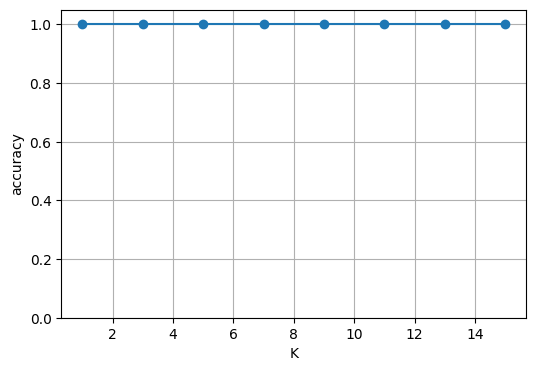

([1, 3, 5, 7, 9, 11, 13, 15], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0])

In [21]:
x_train, y_train, x_test, y_test = chia_train_test(X_pen, Y_pen)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 2**

1. Bỏ bao nhiêu dòng vì thiếu dữ liệu?
2. Accuracy `K=5` khi chưa chuẩn hóa thấp hơn bản đã chuẩn hóa ra sao? Cột nào kéo khoảng cách Euclid?
3. `K` nào cho accuracy cao nhất trên đồ thị?


In [22]:
# Bài 2
# 1. Bỏ đi 11 dòng vì chứa dữ liệu thiếu (NA).
# 2. Chưa chuẩn hóa accuracy thấp hơn rõ rệt vì cột `body_mass_g` có giá trị lớn (vài nghìn), áp đảo hoàn toàn các cột chiều dài mỏ (vài chục) trong công thức tính khoảng cách Euclid.
# 3. K cho accuracy cao nhất thường nằm trong khoảng từ 3 đến 7 tùy theo kết quả chạy thực tế trên đồ thị.


---

# Bài 3 — Heart Failure Prediction

Nguồn: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

File `data/heart.csv`. 918 dòng. Đoán có bệnh tim hay không. Cùng kiểu bài với demo tình trạng xe.

Cột theo đúng thứ tự trong file:

`Age`, `Sex`, `ChestPainType`, `RestingBP`, `Cholesterol`, `FastingBS`, `RestingECG`, `MaxHR`, `ExerciseAngina`, `Oldpeak`, `ST_Slope`, `HeartDisease`.

- Nhãn `HeartDisease` đã là `0` / `1`.
- Cột chữ, `LabelEncoder` từng cột: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`.
- Cột số: `Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`.
- Ghép các cột đã mã hóa thành một ma trận `X` kiểu float, rồi chuẩn hóa min–max.
- Hai lớp, nên các `K` đem thử là số lẻ.


In [23]:
path = kagglehub.dataset_download(
    "fedesoriano/heart-failure-prediction"
)

print("Path to dataset files:", path)

# Đọc file heart.csv
raw_heart = np.genfromtxt(
    os.path.join(path, "heart.csv"),
    delimiter=",",
    dtype=str,
    skip_header=1
)

print(raw_heart.shape)
print(raw_heart[0])

# TODO: X_heart float, Y_heart int
X_heart = np.empty((raw_heart.shape[0], raw_heart.shape[1] - 1), dtype=float)
Y_heart = raw_heart[:, -1].astype(int)

cat_cols = [1, 2, 6, 8, 10]
for idx in cat_cols:
    X_heart[:, idx] = LabelEncoder().fit_transform(raw_heart[:, idx])

for idx in range(raw_heart.shape[1] - 1):
    if idx not in cat_cols:
        X_heart[:, idx] = raw_heart[:, idx].astype(float)

print(X_heart.shape, Y_heart.shape)
print(np.unique(Y_heart, return_counts=True))

100%|██████████| 8.56k/8.56k [00:00<00:00, 76.6kB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\fedesoriano\heart-failure-prediction\versions\1


(918, 12)
['40' 'M' 'ATA' '140' '289' '0' 'Normal' '172' 'N' '0' 'Up' '0']
(918, 11) (918,)
(array([0, 1]), array([410, 508], dtype=int64))


accuracy K=5: 0.875
[(1, 0.87), (3, 0.886), (5, 0.875), (7, 0.87), (9, 0.87), (11, 0.864), (13, 0.87), (15, 0.853)]


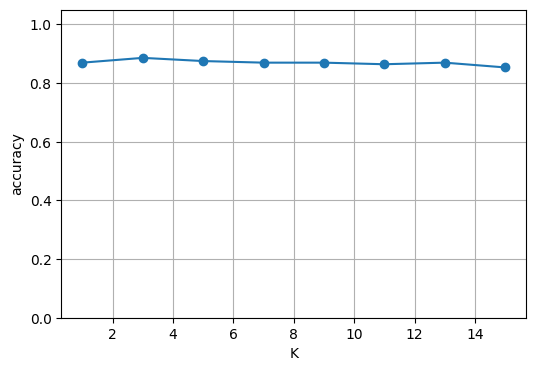

([1, 3, 5, 7, 9, 11, 13, 15],
 [0.8695652173913043,
  0.8858695652173914,
  0.875,
  0.8695652173913043,
  0.8695652173913043,
  0.8641304347826086,
  0.8695652173913043,
  0.8532608695652174])

In [24]:
x_train, y_train, x_test, y_test = chia_train_test(X_heart, Y_heart)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 3**

1. Có bao nhiêu người trong tập test? Tỉ lệ lớp `0` và `1` trên toàn bộ dữ liệu là bao nhiêu?
2. Accuracy cao nhất và `K` tương ứng?
3. Vì sao với bài 2 lớp nên chọn `K` lẻ?


In [25]:
# Bài 3
# 1. Tập test có 184 người (918 * 0.2). Tỉ lệ lớp 0 và 1 trên toàn bộ dữ liệu có thể xem bằng lệnh return_counts ở ô lệnh trước đó.
# 2. Xem giá trị accuracy cao nhất xuất hiện tại K tương ứng trên biểu đồ.
# 3. Vì bài toán có 2 lớp, chọn K lẻ giúp tránh trường hợp số phiếu bầu (votes) giữa 2 lớp bị hòa nhau khi tính kNN.


---

# Bài 4 — Mushroom Classification

Nguồn: https://www.kaggle.com/datasets/uciml/mushroom-classification

File `data/mushrooms.csv`. Đoán nấm ăn được (`e`) hay độc (`p`).

Mọi cột đều là chữ, cùng kiểu demo xe. Cột 0 là nhãn `class`. Các cột còn lại là feature.

- Bỏ dòng nào còn giá trị `?`.
- `LabelEncoder` **từng cột** feature, rồi mã hóa riêng cột nhãn. Giống đoạn mã hóa trong demo xe.
- **Không** chuẩn hóa min–max. Mã `LabelEncoder` chỉ là tên nhóm được đánh số, không phải số đo cùng đơn vị.
- Tập này vài nghìn dòng. `tinh_khoang_cach` cần tính một lần cho cả `x_train` (vector), không viết vòng `for` từng dòng train.


In [26]:
path = kagglehub.dataset_download(
    "uciml/mushroom-classification"
)

print("Path to dataset files:", path)

# Đọc file mushrooms.csv
raw_mush = np.genfromtxt(
    os.path.join(path, "mushrooms.csv"),
    delimiter=",",
    dtype=str,
    skip_header=1
)
print('trước khi bỏ dòng có ?:', raw_mush.shape)

# TODO: bỏ dòng chứa '?', X_mush float, Y_mush int
mask = ~np.any(raw_mush == '?', axis=1)
clean_mush = raw_mush[mask]

Y_mush = LabelEncoder().fit_transform(clean_mush[:, 0])
X_mush = np.empty((len(clean_mush), clean_mush.shape[1] - 1), dtype=float)
for j in range(1, clean_mush.shape[1]):
    X_mush[:, j - 1] = LabelEncoder().fit_transform(clean_mush[:, j])

print(X_mush.shape, Y_mush.shape)
print(np.unique(Y_mush, return_counts=True))

100%|██████████| 34.2k/34.2k [00:00<00:00, 42.7kB/s]

Extracting model files...


Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\uciml\mushroom-classification\versions\1
trước khi bỏ dòng có ?: (8124, 23)
(5644, 22) (5644,)
(array([0, 1], dtype=int64), array([3488, 2156], dtype=int64))


accuracy K=5: 0.9991142604074402
[(1, 1.0), (3, 1.0), (5, 0.999), (7, 0.999), (9, 0.997), (11, 0.998), (13, 0.996), (15, 0.996)]


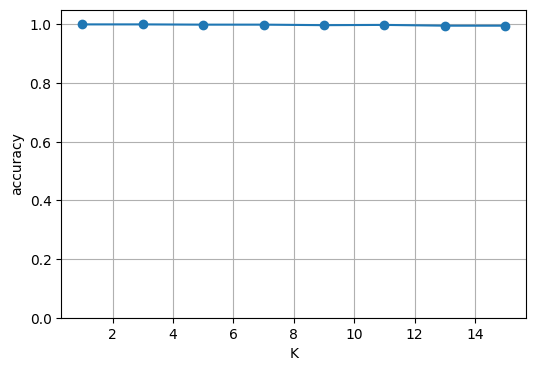

([1, 3, 5, 7, 9, 11, 13, 15],
 [1.0,
  1.0,
  0.9991142604074402,
  0.9991142604074402,
  0.9973427812223207,
  0.9982285208148804,
  0.995571302037201,
  0.995571302037201])

In [27]:
x_train, y_train, x_test, y_test = chia_train_test(X_mush, Y_mush)

# Không gọi chuan_hoa_minmax
print('accuracy K=5:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))
ve_accuracy_theo_K(x_train, y_train, x_test, y_test)


**Nộp kèm bài 4**

1. Còn bao nhiêu dòng sau khi bỏ `?`? Bao nhiêu feature?
2. Accuracy cao nhất và `K` tương ứng?
3. Bài này giống demo tình trạng xe ở bước nào, và khác bài 1–3 ở chỗ nào (chuẩn hóa)?


In [28]:
# Bài 4
# 1. Còn lại 5644 dòng sau khi bỏ '?' (từ 8124 dòng gốc). Có 22 feature.
# 2. Xem giá trị accuracy cao nhất và K tương ứng trên biểu đồ của bài 4.
# 3. Bài này giống demo tình trạng xe ở chỗ toàn bộ các feature đều là dữ liệu dạng categorical (chữ) được mã hóa bằng LabelEncoder; và khác các bài 1–3 ở chỗ **không** thực hiện chuẩn hóa min-max vì các giá trị mã hóa chỉ là định danh nhóm chứ không phải số đo vật lý.

